# Task 2 (Easy) – Content Type Analysis Dashboard
**Auspify Technologies · Data Analysis Using Python Internship**

**Goal:** Analyze the distribution of Movies and TV Shows available on Netflix.

| Step | Description |
|---|---|
| 1 | Load the cleaned dataset |
| 2 | Calculate the total number of Movies and TV Shows |
| 3 | Create visualizations for content distribution |
| 4 | Compare content proportions |
| 5 | Summarize key findings |

In [3]:
import sys
sys.path.insert(0, '../src')   # makes netflix_utils importable from the notebooks folder

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from netflix_utils import *

## Step 1 – Load the cleaned dataset

In [5]:


df = load_clean()
print(f"{len(df):,} titles loaded | columns: {list(df.columns)}")
df.head()

8,786 titles loaded | columns: ['show_id', 'type', 'title', 'director', 'country', 'region', 'date_added', 'year_added', 'month_added', 'release_year', 'rating', 'audience_group', 'duration', 'duration_value', 'duration_unit', 'listed_in', 'primary_genre', 'genre_count', 'director_missing', 'country_missing']


,show_id,type,title,director,country,region,date_added,year_added,month_added,release_year,rating,audience_group,duration,duration_value,duration_unit,listed_in,primary_genre,genre_count,director_missing,country_missing
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,North America,2021-09-25,2021,9,2020,PG-13,Teens,90 min,90,Minutes,Documentaries,Documentaries,1,False,False
1,s3,TV Show,Ganglands,Julien Leclercq,France,Europe,2021-09-24,2021,9,2021,TV-MA,Adults,1 Season,1,Seasons,"Crime TV Shows, International TV Shows, TV Act...",Crime TV Shows,3,False,False
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,North America,2021-09-24,2021,9,2021,TV-MA,Adults,1 Season,1,Seasons,"TV Dramas, TV Horror, TV Mysteries",TV Dramas,3,False,False
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,South America,2021-09-22,2021,9,2021,TV-PG,Older Kids / Family,91 min,91,Minutes,"Children & Family Movies, Comedies",Children & Family Movies,2,False,False
4,s8,Movie,Sankofa,Haile Gerima,United States,North America,2021-09-24,2021,9,1993,TV-MA,Adults,125 min,125,Minutes,"Dramas, Independent Movies, International Movies",Dramas,3,False,False


## Step 2 – Total number of Movies and TV Shows

In [6]:
counts = df["type"].value_counts()
share = (counts / counts.sum() * 100).round(1)
summary = pd.DataFrame({"Titles": counts, "Share %": share})
summary.loc["Total"] = [counts.sum(), 100.0]
n_movies, n_tv, total = int(counts["Movie"]), int(counts["TV Show"]), len(df)
ratio = n_movies / n_tv
print(f"Movies: {n_movies:,} ({share['Movie']}%)  |  TV Shows: {n_tv:,} ({share['TV Show']}%)  |  ratio {ratio:.2f} : 1")
summary

Movies: 6,123 (69.7%)  |  TV Shows: 2,663 (30.3%)  |  ratio 2.30 : 1


,Titles,Share %
type,,
Movie,6123.0,69.7
TV Show,2663.0,30.3
Total,8786.0,100.0


## Step 3 – Visualizations for content distribution

  saved -> outputs\charts\task2_01_type_distribution.png


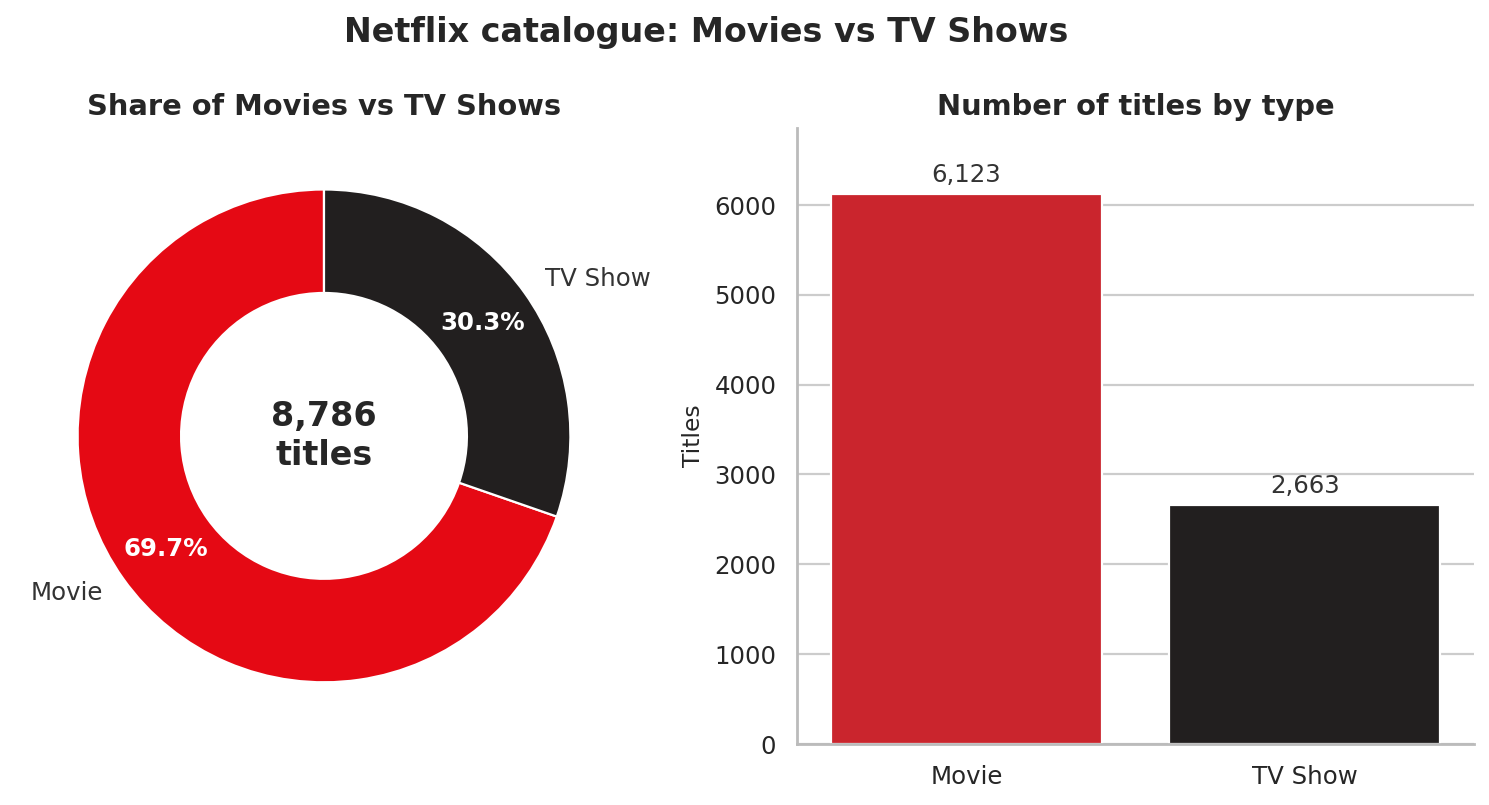

WindowsPath('C:/Users/welcome/Downloads/Task_2_Content_Type_Analysis_Dashboard/Task_2_Content_Type_Analysis_Dashboard/outputs/charts/task2_01_type_distribution.png')

In [7]:
# 3.1 Donut + bar (the headline view)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = [PALETTE["Movie"], PALETTE["TV Show"]]
_, _, ats = axes[0].pie(counts.values, labels=counts.index, colors=colors, startangle=90, autopct="%1.1f%%",
            wedgeprops=dict(width=0.42, edgecolor="white"), textprops=dict(fontsize=11, color="#333"),
            pctdistance=0.79)
for a in ats: a.set_color("white"); a.set_fontweight("bold")
axes[0].text(0, 0, f"{total:,}\ntitles", ha="center", va="center", fontsize=15, fontweight="bold")
axes[0].set_title("Share of Movies vs TV Shows")
sns.barplot(x=counts.index, y=counts.values, palette=colors, ax=axes[1])
label_bars(axes[1], size=11)
axes[1].set_title("Number of titles by type"); axes[1].set_xlabel(""); axes[1].set_ylabel("Titles")
axes[1].set_ylim(0, counts.max() * 1.12)
fig.suptitle("Netflix catalogue: Movies vs TV Shows", fontsize=15, fontweight="bold", y=1.02)
save_fig(fig, "task2_01_type_distribution")

  saved -> outputs\charts\task2_02_type_by_decade.png


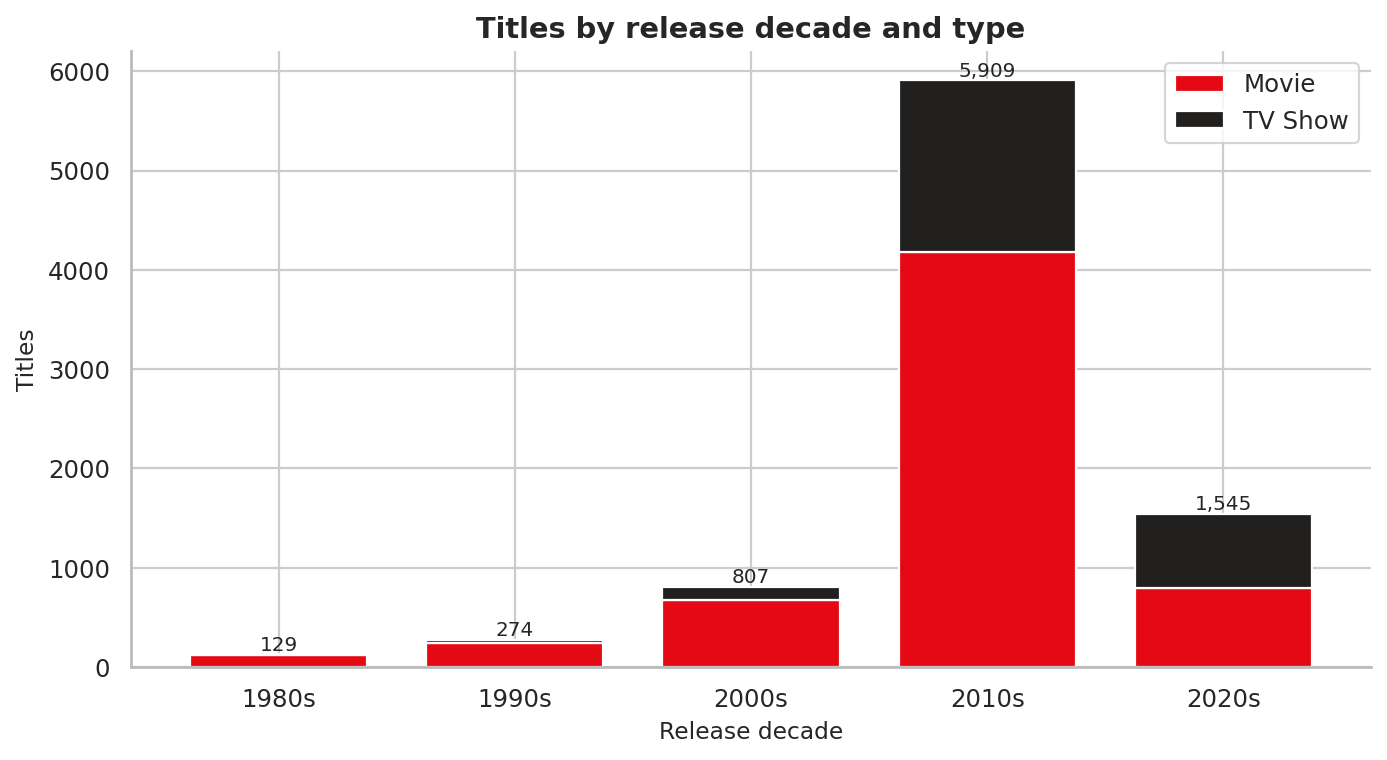

WindowsPath('C:/Users/welcome/Downloads/Task_2_Content_Type_Analysis_Dashboard/Task_2_Content_Type_Analysis_Dashboard/outputs/charts/task2_02_type_by_decade.png')

In [8]:
# 3.2 Content type by release decade (how the catalogue is composed by age)
df["decade"] = (df.release_year // 10 * 10).astype(int)
dec = df[df.decade >= 1980].groupby(["decade", "type"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5))
dec.plot(kind="bar", stacked=True, color=colors, ax=ax, width=0.75)
ax.set_title("Titles by release decade and type"); ax.set_xlabel("Release decade"); ax.set_ylabel("Titles")
ax.set_xticklabels([f"{d}s" for d in dec.index], rotation=0)
for i, (_, r) in enumerate(dec.iterrows()):
    ax.text(i, r.sum() + 40, f"{int(r.sum()):,}", ha="center", fontsize=9)
ax.legend(title="")
save_fig(fig, "task2_02_type_by_decade")

  saved -> outputs\charts\task2_03_added_per_year_by_type.png


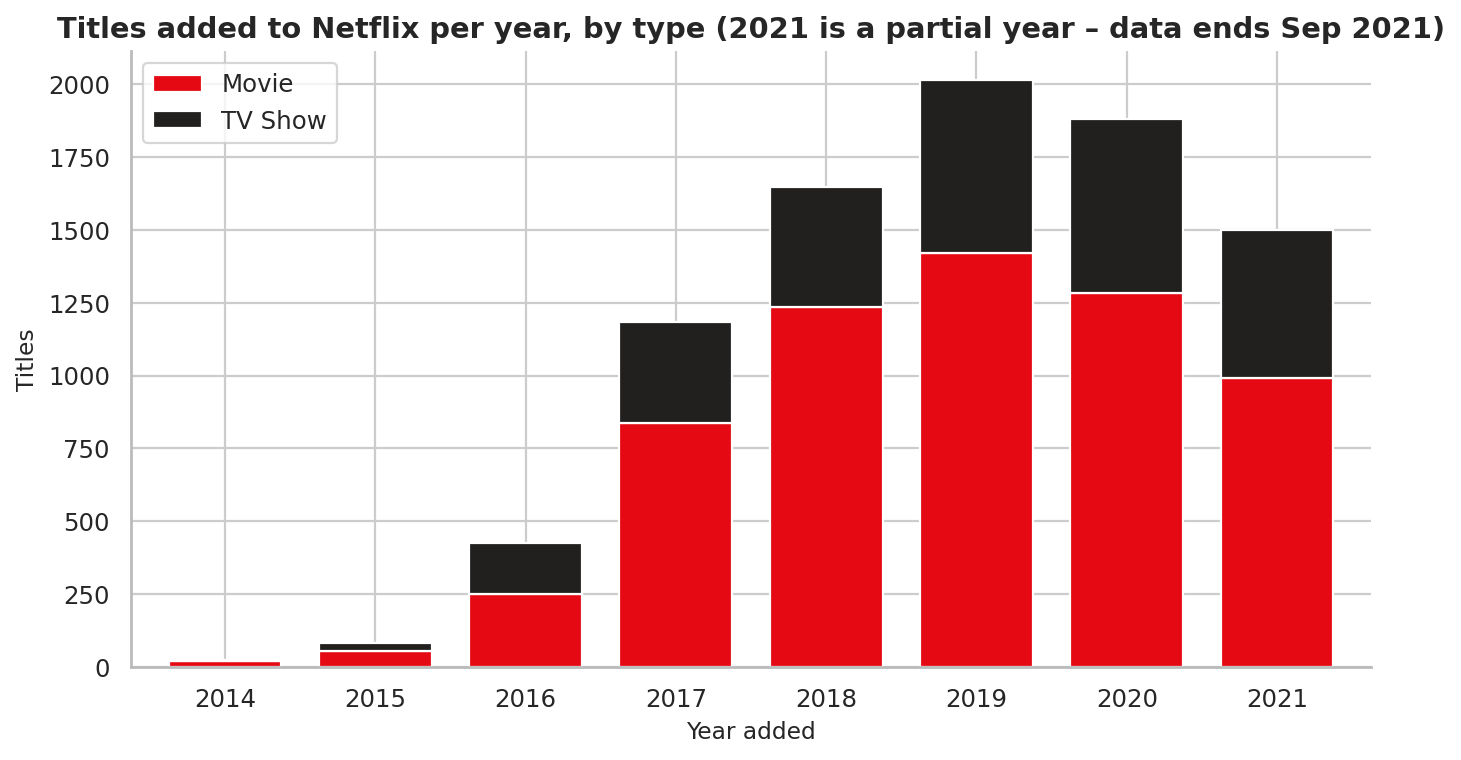

WindowsPath('C:/Users/welcome/Downloads/Task_2_Content_Type_Analysis_Dashboard/Task_2_Content_Type_Analysis_Dashboard/outputs/charts/task2_03_added_per_year_by_type.png')

In [9]:
# 3.3 Yearly additions to Netflix by type (2015+ is where the growth is)
add = df[df.year_added >= 2014].groupby(["year_added", "type"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5))
add.plot(kind="bar", stacked=True, color=colors, ax=ax, width=0.75)
ax.set_title("Titles added to Netflix per year, by type (2021 is a partial year – data ends Sep 2021)")
ax.set_xlabel("Year added"); ax.set_ylabel("Titles"); ax.tick_params(axis="x", rotation=0); ax.legend(title="")
save_fig(fig, "task2_03_added_per_year_by_type")

## Step 4 – Compare content proportions

  saved -> outputs\charts\task2_04_proportion_trend.png


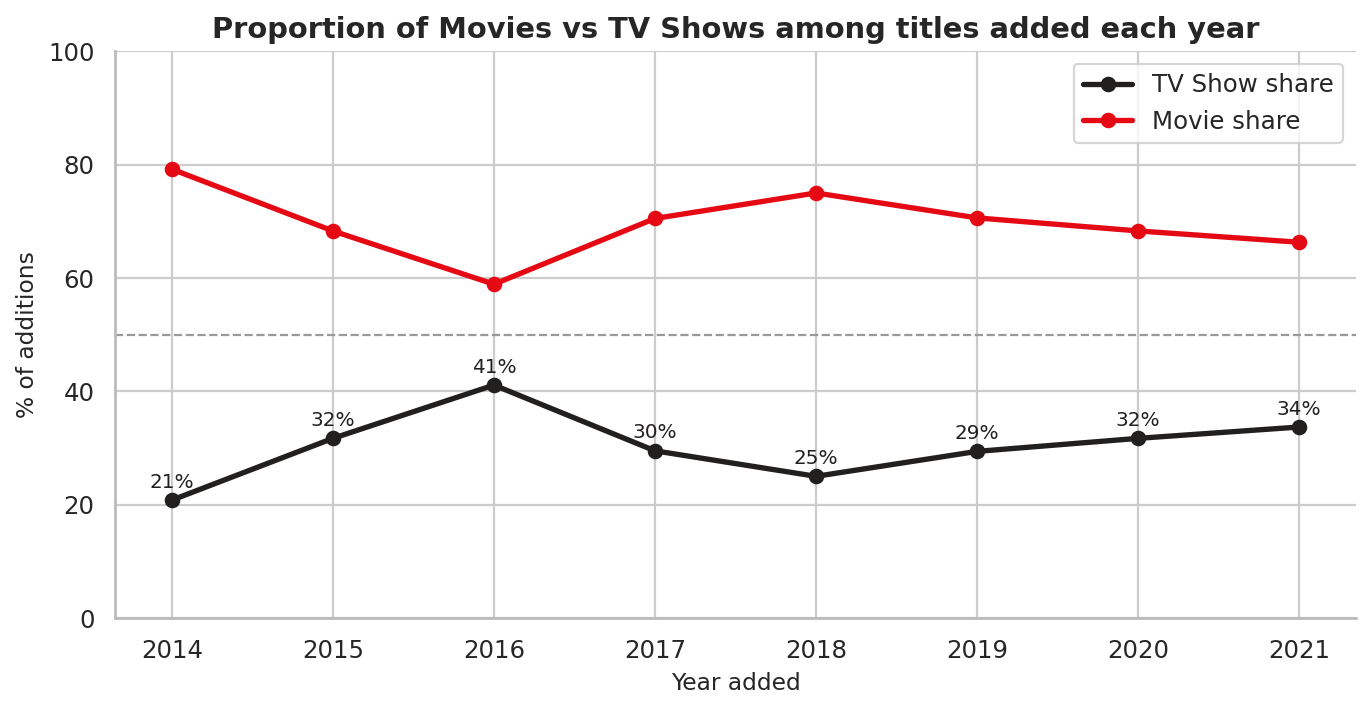

WindowsPath('C:/Users/welcome/Downloads/Task_2_Content_Type_Analysis_Dashboard/Task_2_Content_Type_Analysis_Dashboard/outputs/charts/task2_04_proportion_trend.png')

In [10]:
# 4.1 Share of TV Shows among each year's additions
yr = df[(df.year_added >= 2014)].groupby("year_added")["type"].value_counts(normalize=True).unstack().mul(100).round(1)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(yr.index, yr["TV Show"], marker="o", color=DARK, lw=2.4, label="TV Show share")
ax.plot(yr.index, yr["Movie"], marker="o", color=RED, lw=2.4, label="Movie share")
for x, y in zip(yr.index, yr["TV Show"]):
    ax.text(x, y + 2.2, f"{y:.0f}%", ha="center", fontsize=9, color=DARK)
ax.axhline(50, color="#999", ls="--", lw=1)
ax.set_ylim(0, 100); ax.set_xticks(yr.index)
ax.set_title("Proportion of Movies vs TV Shows among titles added each year")
ax.set_ylabel("% of additions"); ax.set_xlabel("Year added"); ax.legend()
save_fig(fig, "task2_04_proportion_trend")

  saved -> outputs\charts\task2_05_runtime_and_seasons.png


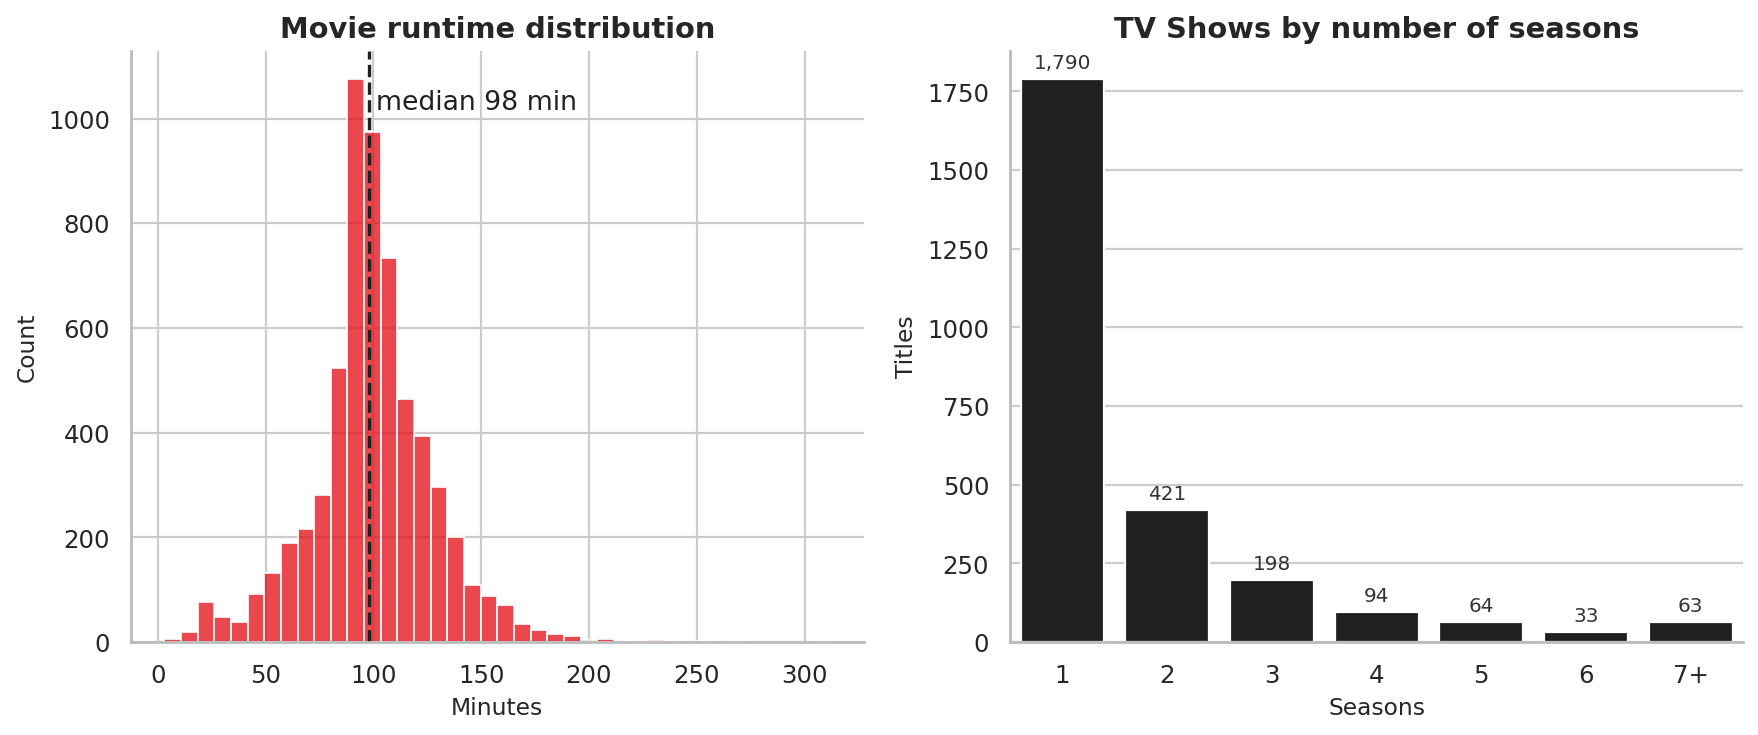

WindowsPath('C:/Users/welcome/Downloads/Task_2_Content_Type_Analysis_Dashboard/Task_2_Content_Type_Analysis_Dashboard/outputs/charts/task2_05_runtime_and_seasons.png')

In [11]:
# 4.2 Average content depth: movie runtime vs number of seasons
mov = df[df.type == "Movie"].duration_value
tv = df[df.type == "TV Show"].duration_value
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(mov, bins=40, color=RED, ax=axes[0])
axes[0].axvline(mov.median(), color=DARK, ls="--"); axes[0].text(mov.median() + 3, axes[0].get_ylim()[1] * 0.9,
    f"median {mov.median():.0f} min", color=DARK)
axes[0].set_title("Movie runtime distribution"); axes[0].set_xlabel("Minutes")
sc = tv.value_counts().sort_index()
sc = pd.concat([sc[sc.index <= 6], pd.Series({"7+": sc[sc.index > 6].sum()})]); sc.index = sc.index.astype(str)
sns.barplot(x=sc.index, y=sc.values, color=DARK, ax=axes[1]); label_bars(axes[1])
axes[1].set_title("TV Shows by number of seasons"); axes[1].set_xlabel("Seasons"); axes[1].set_ylabel("Titles")
save_fig(fig, "task2_05_runtime_and_seasons")

  saved -> outputs\charts\task2_06_type_mix_by_audience.png


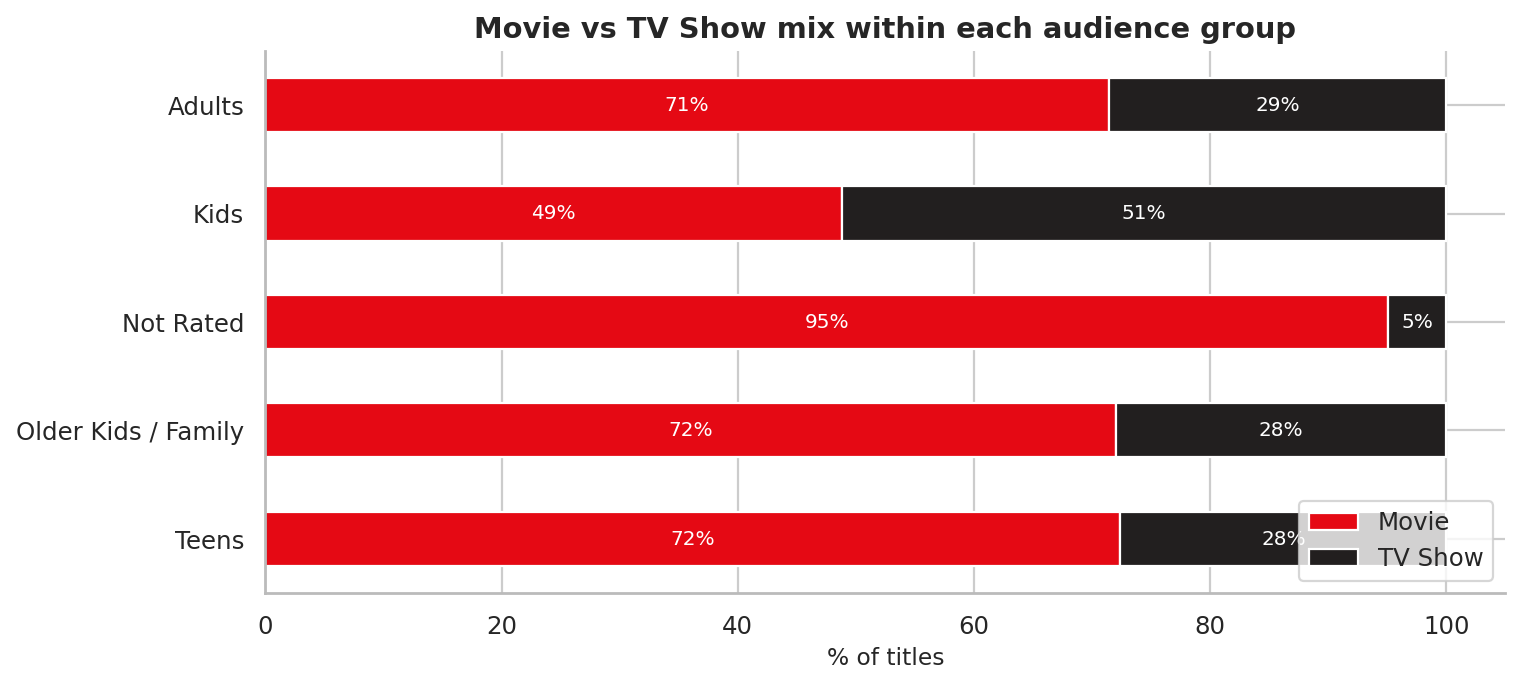

WindowsPath('C:/Users/welcome/Downloads/Task_2_Content_Type_Analysis_Dashboard/Task_2_Content_Type_Analysis_Dashboard/outputs/charts/task2_06_type_mix_by_audience.png')

In [12]:

# 4.3 Type mix by audience group (cross-comparison)
mix = pd.crosstab(df.audience_group, df.type, normalize="index").mul(100).round(1)
fig, ax = plt.subplots(figsize=(10, 4.4))
mix.plot(kind="barh", stacked=True, color=colors, ax=ax)
for i, (_, r) in enumerate(mix.iterrows()):
    ax.text(r["Movie"] / 2, i, f"{r['Movie']:.0f}%", ha="center", va="center", color="white", fontsize=9)
    ax.text(r["Movie"] + r["TV Show"] / 2, i, f"{r['TV Show']:.0f}%", ha="center", va="center", color="white", fontsize=9)
ax.set_title("Movie vs TV Show mix within each audience group"); ax.set_xlabel("% of titles"); ax.set_ylabel(""); ax.legend(title="", loc="lower right")
ax.invert_yaxis()
save_fig(fig, "task2_06_type_mix_by_audience")

### 
Dashboard (all key views on one page)

  saved -> outputs\screenshots\task2_dashboard.png


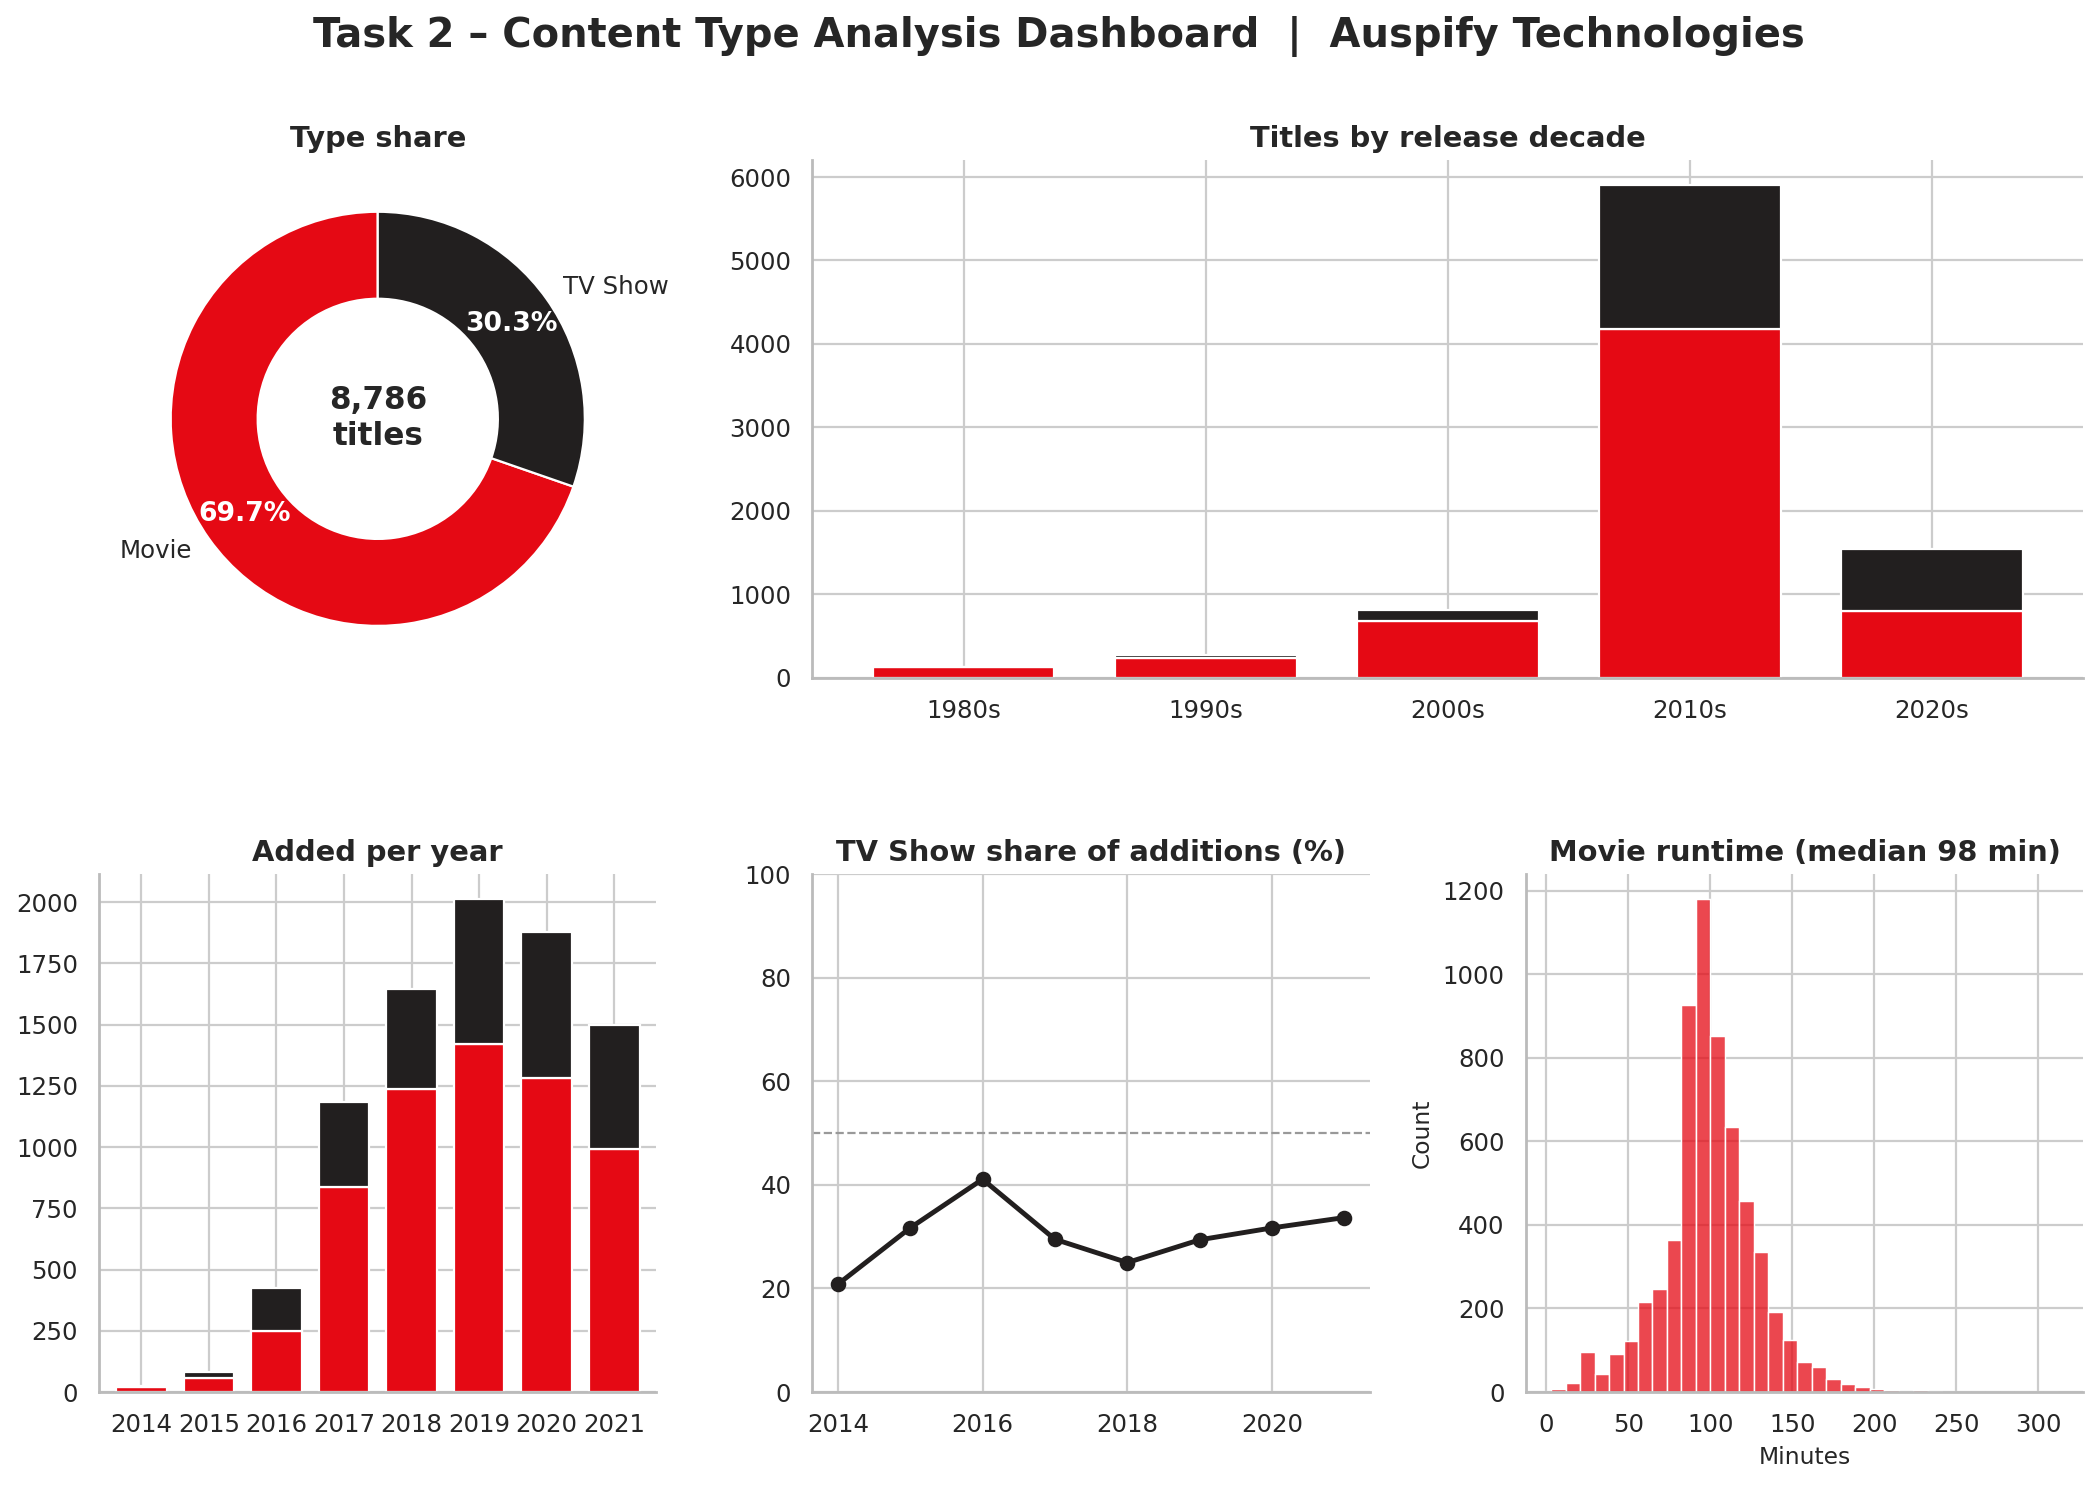

WindowsPath('C:/Users/welcome/Downloads/Task_2_Content_Type_Analysis_Dashboard/Task_2_Content_Type_Analysis_Dashboard/outputs/screenshots/task2_dashboard.png')

In [13]:
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.28)
ax = fig.add_subplot(gs[0, 0])
_, _, ats = ax.pie(counts.values, labels=counts.index, colors=colors, startangle=90, autopct="%1.1f%%",
       wedgeprops=dict(width=0.42, edgecolor="white"), pctdistance=0.79)
for a in ats: a.set_color("white"); a.set_fontweight("bold")
ax.text(0, 0, f"{total:,}\ntitles", ha="center", va="center", fontsize=14, fontweight="bold"); ax.set_title("Type share")
ax = fig.add_subplot(gs[0, 1:])
dec.plot(kind="bar", stacked=True, color=colors, ax=ax, width=0.75, legend=False)
ax.set_xticklabels([f"{d}s" for d in dec.index], rotation=0); ax.set_xlabel(""); ax.set_title("Titles by release decade")
ax = fig.add_subplot(gs[1, 0])
add.plot(kind="bar", stacked=True, color=colors, ax=ax, width=0.75, legend=False)
ax.tick_params(axis="x", rotation=0); ax.set_xlabel(""); ax.set_title("Added per year")
ax = fig.add_subplot(gs[1, 1])
ax.plot(yr.index, yr["TV Show"], marker="o", color=DARK, lw=2.2); ax.axhline(50, color="#999", ls="--", lw=1)
ax.set_ylim(0, 100); ax.set_title("TV Show share of additions (%)"); ax.set_xticks(yr.index[::2])
ax = fig.add_subplot(gs[1, 2])
sns.histplot(mov, bins=35, color=RED, ax=ax); ax.set_title(f"Movie runtime (median {mov.median():.0f} min)"); ax.set_xlabel("Minutes")
fig.suptitle("Task 2 – Content Type Analysis Dashboard  |  Auspify Technologies", fontsize=18, fontweight="bold", y=0.97)
save_fig(fig, "task2_dashboard", SHOTS)

## Step 5 – Summarize key findings

In [14]:
peak_tv_year = int(yr["TV Show"].idxmax())
tv_share_2014 = yr.loc[2014, "TV Show"]
tv_share_latest = yr["TV Show"].iloc[-1]
one_season = pct((tv == 1).sum(), len(tv)); multi = pct((tv >= 3).sum(), len(tv))
long_movies = pct((mov >= 120).sum(), len(mov))
kids_tv_share = float(mix.loc["Kids", "TV Show"]); adult_tv_share = float(mix.loc["Adults", "TV Show"])
metrics = dict(movies=n_movies, tv_shows=n_tv, total=total, movie_share=float(share["Movie"]), tv_share=float(share["TV Show"]),
               ratio=round(ratio, 2), median_runtime=float(mov.median()), mean_runtime=round(float(mov.mean()), 1),
               one_season_pct=one_season, three_plus_seasons_pct=multi, movies_120plus_pct=long_movies,
               tv_share_additions={int(k): float(v) for k, v in yr["TV Show"].items()},
               kids_tv_share=kids_tv_share, adults_tv_share=adult_tv_share, peak_tv_share_year=peak_tv_year)
save_metrics("task2", metrics)

findings = f"""# Task 2 – Content Type Analysis: Summary of Key Findings

| Type | Titles | Share |
|---|---|---|
| Movies | {n_movies:,} | {share['Movie']}% |
| TV Shows | {n_tv:,} | {share['TV Show']}% |
| **Total** | **{total:,}** | 100% |

## Key findings
1. **Movies dominate the catalogue** – {n_movies:,} movies vs {n_tv:,} TV shows, a ratio of **{ratio:.1f} movies for every TV show**.
2. **TV's share of additions is rising but still a minority.** TV shows were **{tv_share_2014:.0f}%** of additions in 2014,
   peaked at **{yr['TV Show'].max():.0f}% in {peak_tv_year}**, dipped to about 25-30% in 2017-2019 and recovered to
   **{tv_share_latest:.0f}%** in the latest (partial) year. TV never exceeded half of a year's additions.
3. **Movies are standard length** – median runtime {mov.median():.0f} minutes; only {long_movies}% run 2 hours or more.
4. **TV is mostly short-run** – {one_season}% of series have a single season and only {multi}% have three or more,
   i.e. most series in the catalogue have not (yet) been renewed beyond their first run.
5. **Audience mix differs by type** – TV shows form {kids_tv_share:.0f}% of Kids content but {adult_tv_share:.0f}% of Adults content.
6. **Catalogue age** – the bulk of titles were released in the 2010s and 2020s; older decades are a small share (see decade chart).

## Visualizations produced
`outputs/charts/task2_01 … task2_06`, dashboard screenshot: `outputs/screenshots/task2_dashboard.png`.

*Note: the dataset ends in September 2021, so 2021 is a partial year.*
"""
write_report("task2_summary.md", findings)
print(findings)

  report -> outputs\reports\task2_summary.md
# Task 2 – Content Type Analysis: Summary of Key Findings

| Type | Titles | Share |
|---|---|---|
| Movies | 6,123 | 69.7% |
| TV Shows | 2,663 | 30.3% |
| **Total** | **8,786** | 100% |

## Key findings
1. **Movies dominate the catalogue** – 6,123 movies vs 2,663 TV shows, a ratio of **2.3 movies for every TV show**.
2. **TV's share of additions is rising but still a minority.** TV shows were **21%** of additions in 2014,
   peaked at **41% in 2016**, dipped to about 25-30% in 2017-2019 and recovered to
   **34%** in the latest (partial) year. TV never exceeded half of a year's additions.
3. **Movies are standard length** – median runtime 98 minutes; only 19.5% run 2 hours or more.
4. **TV is mostly short-run** – 67.2% of series have a single season and only 17.0% have three or more,
   i.e. most series in the catalogue have not (yet) been renewed beyond their first run.
5. **Audience mix differs by type** – TV shows form 51% of Kids conte